In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import cifar100


from tensorflow.keras import layers, models, datasets, applications
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report

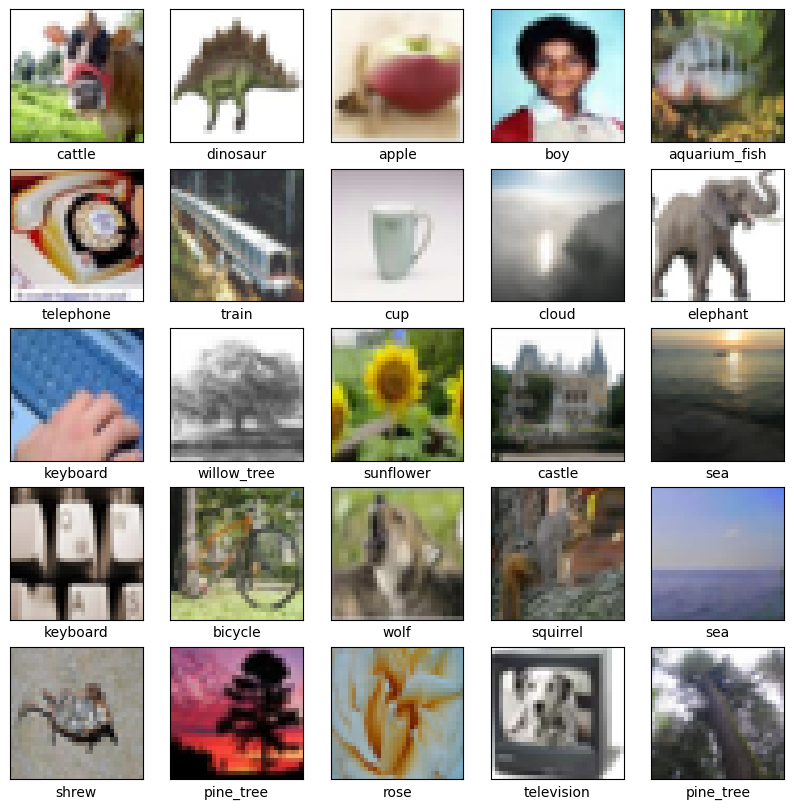

In [2]:
# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar100.load_data()

# Input image dimensions
#img_rows, img_cols = 32, 32
#input_shape = (img_rows, img_cols, 3)

# Resize images (if needed) - CIFAR-10 images are already 32x32
#x_train = tf.image.resize(x_train, [img_rows, img_cols]).numpy()
#x_test = tf.image.resize(x_test, [img_rows, img_cols]).numpy()

# Display some images with their class labels
class_names = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle',
    'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle',
    'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard',
    'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain',
    'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree',
    'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket',
    'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider',
    'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor',
    'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

# Normalize pixel values
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# Split the dataset into training and validation sets
val_split = 0.2
val_samples = int(len(x_train) * val_split)
x_val = x_train[:val_samples]
y_val = y_train[:val_samples]
x_train = x_train[val_samples:]
y_train = y_train[val_samples:]


# Transfer Learning Using Pre-trained CNN Models

In [3]:
# Transfer Learning Using Pre-trained CNN Models
img_size = 75
pre_trained_models = {
    "ResNet50": applications.ResNet50(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3)),
    "VGG16": applications.VGG16(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))
    #"AlexNet": applications.AlexNet(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))
}

results = {}

for model_name, base_model in pre_trained_models.items():
    # Freeze the base model
    base_model.trainable = False

    # Add custom classification head
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dense(100, activation='softmax')
    ])

    # Display the model architecture
    print(f"\nModel Architecture: {model_name}")
    model.summary()


Model Architecture: ResNet50


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,137,956 (92.08 MB)

 Trainable params: 550,244 (2.10 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,871,716 (56.73 MB)

 Trainable params: 157,028 (613.39 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

# Training the Model

In [4]:

# Resize training and validation data to match the input shape of the pre-trained models
img_size = 75  # Assuming this is the input size for your pre-trained models
x_train_new = tf.image.resize(x_train, [img_size, img_size]).numpy()
x_val_new = tf.image.resize(x_val, [img_size, img_size]).numpy()

# One-hot encode the labels if they are not already
y_train_new = to_categorical(y_train, num_classes=100)
y_val_new = to_categorical(y_val, num_classes=100)

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

history = model.fit(x_train_new, y_train_new,
                    epochs=5,
                    batch_size=32,
                    validation_data=(x_val_new, y_val_new),
                    callbacks=[early_stopping])

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 41ms/step - accuracy: 0.1549 - loss: 3.7296 - val_accuracy: 0.2983 - val_loss: 2.7636
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 73s 38ms/step - accuracy: 0.3395 - loss: 2.6059 - val_accuracy: 0.3457 - val_loss: 2.5504
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 82s 38ms/step - accuracy: 0.3821 - loss: 2.3907 - val_accuracy: 0.3653 - val_loss: 2.4416
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 83s 39ms/step - accuracy: 0.4131 - loss: 2.2596 - val_accuracy: 0.3738 - val_loss: 2.4196
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 81s 38ms/step - accuracy: 0.4344 - loss: 2.1620 - val_accuracy: 0.3868 - val_loss: 2.3712


<!-- Evaluation and Results -->


# Evaluation metrics

In [5]:
results = {}

for model_name, base_model in pre_trained_models.items():
    # ... (model creation and training) ...

    # Store results for the current model inside the loop
    results[model_name] = {
        "history": history,
        "model": model
    }

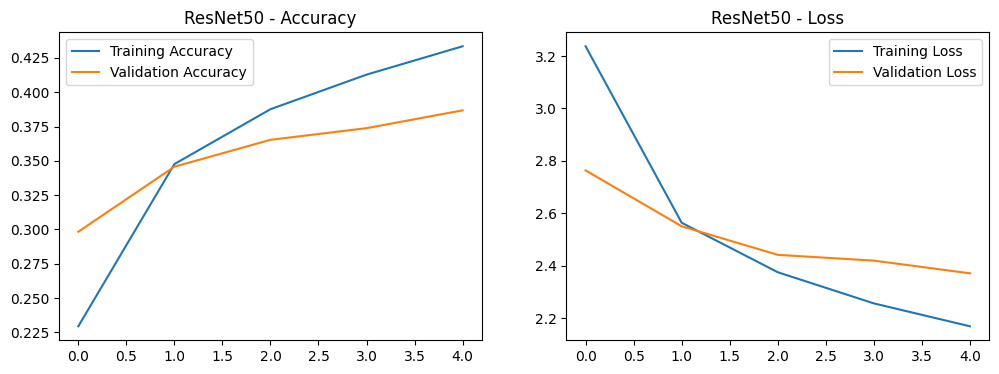

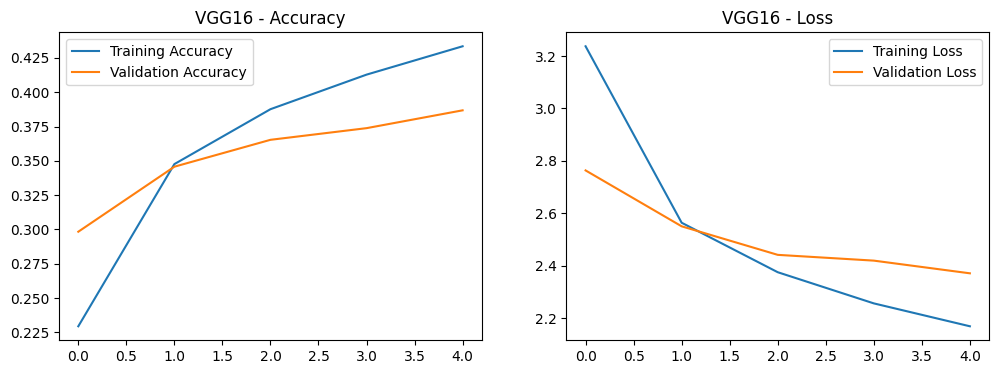

In [6]:
# Plot training and validation accuracy and loss
for model_name, result in results.items():
    history = result["history"]
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.legend()
    plt.title(f'{model_name} - Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.legend()
    plt.title(f'{model_name} - Loss')
    plt.show()

In [7]:
# Normalize test data (missing step in original code)
x_test_normalized = x_test.astype('float32') / 255
# Resize test data before using it for prediction
img_size = 75  # Assuming this is the input size for your pre-trained models
x_test_resized = tf.image.resize(x_test, [img_size, img_size]).numpy()
#Convert y_test to categorical
y_test_categorical = to_categorical(y_test, num_classes=100)

In [8]:
# Continue with the evaluation and results section
for model_name, result in results.items():
    model = result["model"]
    # Use resized test data for prediction
    y_pred = model.predict(x_test_resized)  # Now using the resized data
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test_categorical, axis=1)  # Now using categorical y_test

    # Use resized test data for evaluation
    loss, accuracy = model.evaluate(x_test_resized, y_test_categorical)  # Now using categorical y_test
    print(f"\n{model_name} - Test Loss: {loss}, Test Accuracy: {accuracy}")

    print(f"\n{model_name} - Classification Report:")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.3913 - loss: 2.3493

ResNet50 - Test Loss: 2.3463361263275146, Test Accuracy: 0.39149999618530273

ResNet50 - Classification Report:
               precision    recall  f1-score   support

        apple       0.83      0.64      0.72       100
aquarium_fish       0.56      0.29      0.38       100
         baby       0.32      0.34      0.33       100
         bear       0.17      0.26      0.21       100
       beaver       0.15      0.10      0.12       100
          bed       0.54      0.31      0.39       100
          bee       0.35      0.39      0.37       100
       beetle       0.45      0.39      0.42       100
      bicycle       0.44      0.48      0.46       100
       bottle       0.87      0.46      0.60       100
         bowl       0.41      0.39      0.40       100
          boy       0.24      0.09      0.13       100
       bridge       0.51      0.44      0.47       1

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


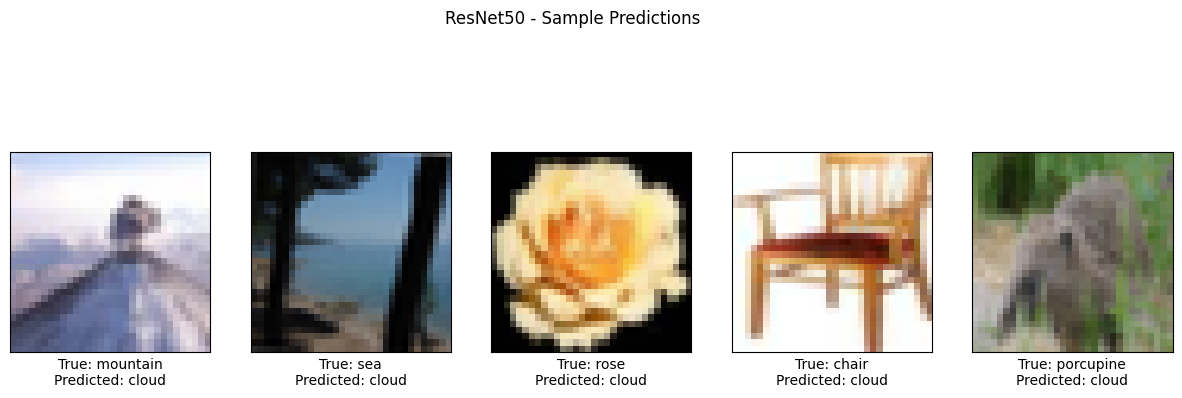

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


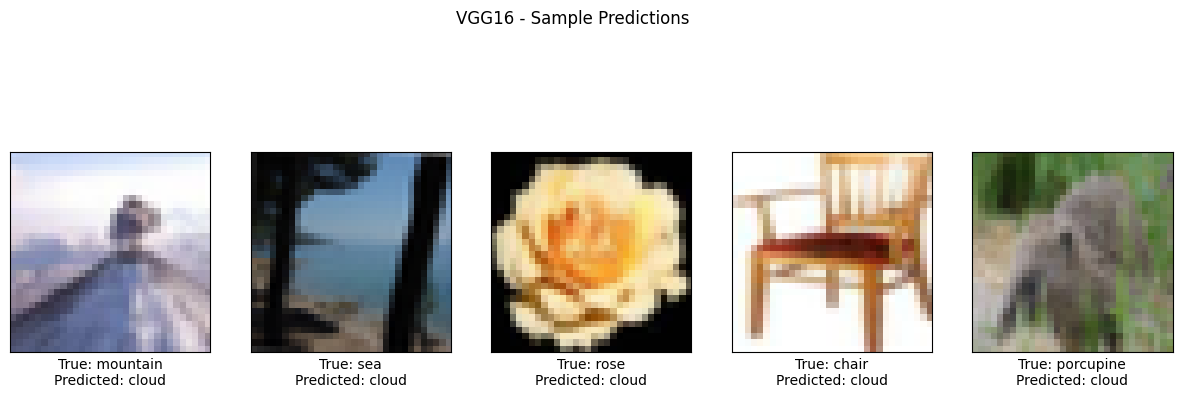

In [9]:
# Predict on sample images
sample_indices = [0, 10, 20, 30, 40]
for model_name, result in results.items():
    model = result["model"]
    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(sample_indices):
        plt.subplot(1, len(sample_indices), i + 1)
        plt.imshow(x_test[idx])
        plt.xticks([])
        plt.yticks([])
        true_label = class_names[y_test[idx][0]]
        prediction = model.predict(np.expand_dims(x_test_normalized[idx], axis=0))
        predicted_label = class_names[np.argmax(prediction)]
        plt.xlabel(f"True: {true_label}\nPredicted: {predicted_label}")
    plt.suptitle(f"{model_name} - Sample Predictions")
    plt.show()

In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

def build_alexnet(input_shape=(75, 75, 3), num_classes=100):
    model = Sequential([
        Conv2D(filters=96, kernel_size=(11, 11), strides=(4, 4), activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling2D(pool_size=(3, 3), strides=(2, 2)),
        Conv2D(filters=256, kernel_size=(5, 5), strides=(1, 1), activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(pool_size=(3, 3), strides=(2, 2)),
        Conv2D(filters=384, kernel_size=(3, 3), strides=(1, 1), activation='relu', padding='same'),
        Conv2D(filters=384, kernel_size=(3, 3), strides=(1, 1), activation='relu', padding='same'),
        Conv2D(filters=256, kernel_size=(3, 3), strides=(1, 1), activation='relu', padding='same'),
        MaxPooling2D(pool_size=(3, 3), strides=(2, 2)),
        Flatten(),
        Dense(4096, activation='relu'),
        Dropout(0.5),
        Dense(4096, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model



In [2]:
alexnet_model = build_alexnet()
alexnet_model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 17, 17, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 17, 17, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 256)      │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 3, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     1,052,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │       409,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,992,292 (83.89 MB)

 Trainable params: 21,991,588 (83.89 MB)

 Non-trainable params: 704 (2.75 KB)

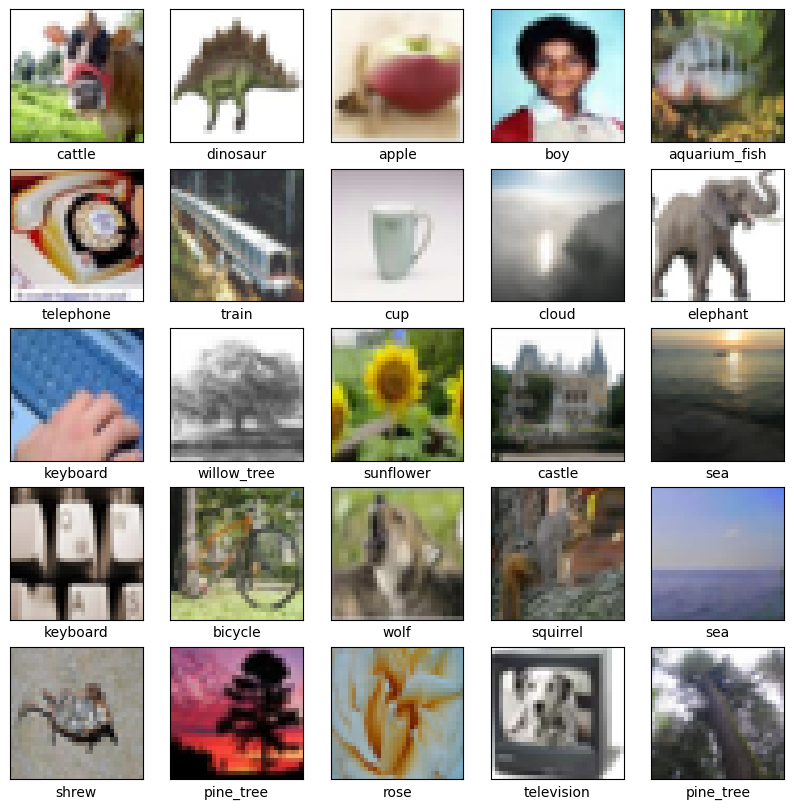

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 19ms/step - accuracy: 0.0191 - loss: 4.5306 - val_accuracy: 0.0557 - val_loss: 4.1695
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.0605 - loss: 4.0752 - val_accuracy: 0.0756 - val_loss: 3.8998
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.0894 - loss: 3.8727 - val_accuracy: 0.1149 - val_loss: 3.7244
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.1167 - loss: 3.7083 - val_accuracy: 0.1126 - val_loss: 3.7782
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.1369 - loss: 3.5771 - val_accuracy: 0.1560 - val_loss: 3.5132


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import cifar100
from tensorflow.keras.utils import to_categorical


from tensorflow.keras import layers, models, datasets, applications

# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar100.load_data()

# Input image dimensions
#img_rows, img_cols = 32, 32
#input_shape = (img_rows, img_cols, 3)

# Resize images (if needed) - CIFAR-10 images are already 32x32
#x_train = tf.image.resize(x_train, [img_rows, img_cols]).numpy()
#x_test = tf.image.resize(x_test, [img_rows, img_cols]).numpy()

# Display some images with their class labels
class_names = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle',
    'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle',
    'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard',
    'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain',
    'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree',
    'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket',
    'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider',
    'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor',
    'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

# Normalize pixel values
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# Split the dataset into training and validation sets
val_split = 0.2
val_samples = int(len(x_train) * val_split)
x_val = x_train[:val_samples]
y_val = y_train[:val_samples]
x_train = x_train[val_samples:]
y_train = y_train[val_samples:]







# Resize training and validation data to match the input shape of the pre-trained models
img_size1 = 75  # Assuming this is the input size for your pre-trained models
x_train_new1 = tf.image.resize(x_train, [img_size1, img_size1]).numpy()
x_val_new1 = tf.image.resize(x_val, [img_size1, img_size1]).numpy()

# One-hot encode the labels if they are not already
y_train_new1 = to_categorical(y_train, num_classes=100)
y_val_new1 = to_categorical(y_val, num_classes=100)

alexnet_model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

history = alexnet_model.fit(x_train_new1, y_train_new1,
                    epochs=5,
                    batch_size=32,
                    validation_data=(x_val_new1, y_val_new1),
                    callbacks=[early_stopping])

In [7]:
history.history

{'accuracy': [0.028725000098347664,
  0.06700000166893005,
  0.09412500262260437,
  0.11919999867677689,
  0.1407250016927719],
 'loss': [4.399065017700195,
  4.029306411743164,
  3.842820405960083,
  3.6836419105529785,
  3.5615639686584473],
 'val_accuracy': [0.05570000037550926,
  0.07559999823570251,
  0.11490000039339066,
  0.11259999871253967,
  0.15600000321865082],
 'val_loss': [4.169500827789307,
  3.8998165130615234,
  3.72442889213562,
  3.7781870365142822,
  3.513170003890991]}

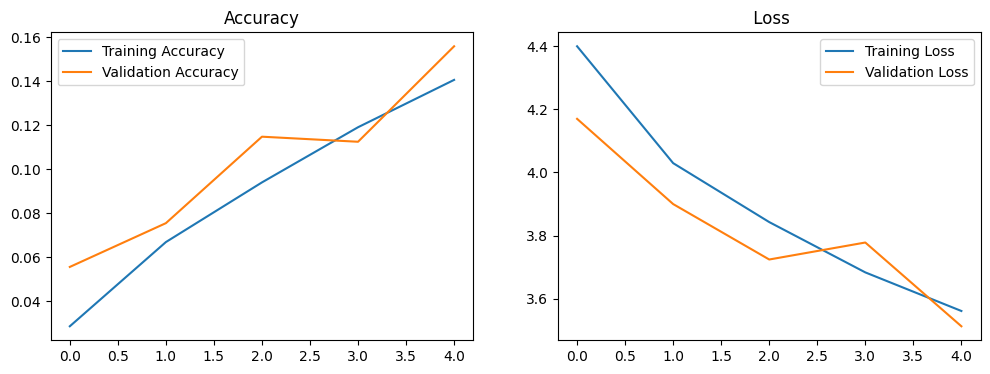

In [8]:
# Plot training and validation accuracy and loss
# history = history.history # Remove this line
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title(f' Loss')
plt.show()